# RF 실험 1 · 특징 그룹 단독 학습 (Group-only)

**질문: g1~g6 각각의 정보만으로 웹사이트를 얼마나 구별할 수 있을까?**
전체 특징 110개를 기준으로 두고, g1~g6을 하나씩 단독 사용합니다. 그룹을 제거하는 Ablation과는 다른 실험입니다.

| 항목 | 실행 조건 |
| --- | --- |
| 주 실험 | Closed-world 95개 사이트 / Open-world 다중 96클래스 |
| 보조 실험 | Open-world 이진 (기본 생략, 설정으로 실행 가능) |
| 특징 조건 | full + g1 + g2 + g3 + g4 + g5 + g6 = 7조건 |
| 입력 | 기존 trim0 CSV 2개, g6 누적 흐름 50지점 |
| RF | 트리 100개, 깊이 20, max_features="sqrt", 최소 리프 1, seed 42 |
| 평가 | 기존 공유 train/test 분할 + 학습 데이터 내부 층화 5-fold |
| 전처리 | 표준화·로그 변환·상수 제거 없이 기존 110개 특징 유지 |

이전 `MLB_RandomForest.ipynb` 실행본에서 세 과제 모두 선택된 RF 설정을 고정했습니다.
그룹마다 다시 튜닝하지 않습니다. 이전의 깊이 제한 없는 기본 RF와는 구분합니다.

**기본 실행량:** 2과제 × 7조건 × (5개 CV 학습 + 최종 학습 1회) = **84회 fit**.
후보를 여러 개 탐색하지 않으며, 적은 특징을 쓰는 조건은 전체 특징 조건보다 빨리 끝날 수 있습니다.
CPU 런타임으로 실행하세요. scikit-learn RF는 이 코드에서 GPU를 사용하지 않습니다.

**사용 순서**
1. 0번 셀에서 `FEATURE_DIR`, `RESULT_ROOT`, `SPLIT_PATH` 확인.
2. 위에서부터 모두 실행. 기존 `split_seed42.csv`가 있어야 기본 설정으로 진행됩니다.
3. 4번 Closed-world, 5번 Open-world 다중 결과를 확인하고 7번 보고서용 표를 사용.

**중단 후:** 같은 파일·설정으로 다시 실행하면 끝난 CV fold와 완료 조건을 재사용합니다.
중단 당시 학습 중이던 fold/최종 학습은 다시 시작합니다. 모델 자체를 저장하는 노트북은 아닙니다.
로그는 조건별 시작·완료와 5분 간격의 실제 완료 fold 수만 표시합니다.

**8번째 패킷 관련:** 조교님 답변이 아직 이 노트북에 제공되지 않았으므로 특징 사용 제한을 임의로 만들지 않았습니다.
기본 Open-world 결과는 원래 특징을 사용한 **해석 보류 결과**입니다. 답변에 따라 0번의 제외 열과 해석 메모를 설정하고 재실행하세요.


## 0. 설정 · 드라이브 연결

보조 이진 실험은 `RUN_BINARY=True`로 바꾸면 실행됩니다. 42회 fit이 추가됩니다.


In [39]:
FEATURE_DIR = "/content/drive/MyDrive/MLB-Project/feature"
RESULT_ROOT = "/content/drive/MyDrive/MLB-Project/results"
SPLIT_PATH = RESULT_ROOT + "/split_seed42.csv"
RESULT_DIR = RESULT_ROOT + "/rf_experiment1_group_only"

RUN_BINARY = True
SEED = 42
N_FOLDS = 5
N_JOBS = -1  # RF 트리 학습에 사용; CV fold는 순차 실행해 CPU 중첩을 피합니다.
TEST_SIZE = 0.2
EXPECTED_MON_CLASSES = 95
ALLOW_CREATE_SHARED_SPLIT = False  # 기존 LR/RF와 같은 분할을 사용하는 것이 기본입니다.
USE_CACHE = True
LOG_INTERVAL_SECONDS = 300

RF_PARAMS = dict(n_estimators=100, max_depth=20,
                 max_features="sqrt", min_samples_leaf=1,
                 class_weight=None)


In [40]:
import os, sys, json, time, threading, tempfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from joblib import hash as joblib_hash
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    from google.colab import drive
except ImportError:
    drive = None
if drive is not None:
    drive.mount("/content/drive")

Path(RESULT_DIR).mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
GROUP_SIZES = {"g1":3, "g2":17, "g3":6, "g4":3, "g5":31, "g6":50}
GROUP_NAMES = {"g1":"패킷 개수·비율", "g2":"송신 순서·위치",
               "g3":"연속 방향 묶음", "g4":"초반·후반 방향 비율",
               "g5":"시간·속도", "g6":"누적 흐름 50지점"}
CONDITIONS = ["full", *GROUP_SIZES]
if not isinstance(N_FOLDS, int) or N_FOLDS < 2 or LOG_INTERVAL_SECONDS <= 0:
    raise ValueError("N_FOLDS와 LOG_INTERVAL_SECONDS 설정을 확인하세요.")
if RF_PARAMS["max_features"] != "sqrt":
    raise ValueError("기존 RF와 비교하려면 max_features='sqrt'를 유지하세요.")
print("scikit-learn:", sklearn.__version__, "| CPU RF | 별도 하이퍼파라미터 탐색 없음")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
scikit-learn: 1.6.1 | CPU RF | 별도 하이퍼파라미터 탐색 없음


## 1. 입력 점검 · 실제 그룹별 열 확인

정답·ID 등 정보 열 6개는 입력에서 제외합니다. 그룹은 열 이름의 `g1_`~`g6_` 접두사로 나눕니다.
`feature_groups.csv`에 **각 그룹에 속하는 실제 열 이름 전부**를 저장합니다.
`max_features="sqrt"`라는 규칙은 모든 조건에서 같지만, 특징 수가 작아지면 분기에서 고려하는 특징 수도 작아집니다.
아래 `split_feature_budget`은 그 규칙의 명목상 개수입니다. 유효한 분할을 찾는 과정에서는 더 많은 특징을 확인할 수도 있습니다.
따라서 단독 성능 차이를 정보량만의 순수한 차이라고 단정하지 않습니다.


In [41]:
INFO_COLS = ["record_id", "dataset", "page_id", "sample_idx", "label", "trim"]

def load_csv(kind):
    base = Path(FEATURE_DIR)
    candidates = [base/f"features_{kind}_trim0_cumul50.csv",
                  base/f"features_{kind}_trim0.csv"]
    path = next((p for p in candidates if p.is_file()), None)
    if path is None:
        raise FileNotFoundError("FEATURE_DIR에서 찾지 못했습니다: " + ", ".join(map(str, candidates)))
    df = pd.read_csv(path, dtype={"record_id":str})
    if df.columns[:6].tolist() != INFO_COLS:
        raise ValueError(f"정보 열 6개와 순서를 확인하세요: {path.name}")
    feats = [c for c in df if any(c.startswith(g+"_") for g in GROUP_SIZES)]
    actual = {g:sum(c.startswith(g+"_") for c in feats) for g in GROUP_SIZES}
    if actual != GROUP_SIZES or set(df.columns) != set(INFO_COLS+feats):
        raise ValueError(f"trim0 / 50지점 / 110특징 CSV가 필요합니다. 실제 그룹: {actual}")
    if df.record_id.isna().any() or df.record_id.duplicated().any():
        raise ValueError(f"record_id 누락/중복: {path.name}")
    if not df.dataset.eq(kind).all() or not df.trim.eq(0).all():
        raise ValueError(f"dataset/trim 불일치: {path.name}")
    if df.label.isna().any() or not np.equal(df.label, np.floor(df.label)).all():
        raise ValueError("라벨이 정수가 아닙니다.")
    df["label"] = df.label.astype(int)
    if kind == "mon" and not df.label.ge(0).all():
        raise ValueError("mon 라벨은 0 이상의 사이트 번호여야 합니다.")
    if kind != "mon" and not df.label.eq(-1).all():
        raise ValueError("unmon 라벨은 -1이어야 합니다.")
    if not np.isfinite(df[feats].to_numpy(dtype=float)).all():
        raise ValueError(f"NaN/inf 특징이 있습니다: {path.name}")
    print(f"{path.name}: {len(df):,}건 / {len(feats)}특징")
    return df, feats, path

mon, FEATS, MON_PATH = load_csv("mon")
unmon, ufeats, UNMON_PATH = load_csv("unmon10k")
if FEATS != ufeats or set(mon.record_id) & set(unmon.record_id):
    raise ValueError("mon/unmon의 특징 순서가 다르거나 ID가 겹칩니다.")
if sorted(mon.label.unique()) != list(range(EXPECTED_MON_CLASSES)):
    raise ValueError(f"mon 라벨 0~{EXPECTED_MON_CLASSES-1}을 기대합니다.")
GROUP_COLS = {g:[c for c in FEATS if c.startswith(g+"_")] for g in GROUP_SIZES}
FEATURE_MAP = pd.DataFrame([dict(group=g, meaning=GROUP_NAMES[g], feature=c)
                            for g,cols in GROUP_COLS.items() for c in cols])
group_table = pd.DataFrame([dict(group=g, meaning=GROUP_NAMES.get(g,"전체 특징"), n_features=len(cols),
                               split_feature_budget=max(1,int(np.sqrt(len(cols)))))
                           for g,cols in {"full":FEATS, **GROUP_COLS}.items()])
display(group_table)
for g, cols in GROUP_COLS.items():
    print(f"{g}: " + ", ".join(cols))


features_mon_trim0.csv: 19,000건 / 110특징
features_unmon10k_trim0.csv: 10,000건 / 110특징


,group,meaning,n_features,split_feature_budget
0,full,전체 특징,110,10
1,g1,패킷 개수·비율,3,1
2,g2,송신 순서·위치,17,4
3,g3,연속 방향 묶음,6,2
4,g4,초반·후반 방향 비율,3,1
5,g5,시간·속도,31,5
6,g6,누적 흐름 50지점,50,7


g1: g1_n_total, g1_n_out, g1_in_ratio
g2: g2_out_pos_mean, g2_out_pos_std, g2_chunk20_mean, g2_chunk20_std, g2_chunk20_max, g2_chunk20_min, g2_chunk20_median, g2_chunk50_mean, g2_chunk50_std, g2_chunk50_max, g2_chunk50_min, g2_chunk50_median, g2_chunk100_mean, g2_chunk100_std, g2_chunk100_max, g2_chunk100_min, g2_chunk100_median
g3: g3_n_out_bursts, g3_bursts_len1_5, g3_bursts_len6_20, g3_bursts_len21p, g3_max_out_burst, g3_max_in_burst
g4: g4_first30_out_ratio, g4_first100_out_ratio, g4_last30_out_ratio
g5: g5_duration, g5_pps_mean, g5_pps_std, g5_pps_max, g5_pps_min, g5_pps_median, g5_rel_t25, g5_rel_t50, g5_rel_t75, g5_iat_all_mean, g5_iat_all_std, g5_iat_all_max, g5_iat_all_q25, g5_iat_all_q50, g5_iat_all_q75, g5_iat_out_mean, g5_iat_out_std, g5_iat_out_max, g5_iat_out_q25, g5_iat_out_q50, g5_iat_out_q75, g5_iat_in_mean, g5_iat_in_std, g5_iat_in_max, g5_iat_in_q25, g5_iat_in_q50, g5_iat_in_q75, g5_iat_zero_ratio, g5_iat_pos_mean, g5_iat_pos_std, g5_iat_pos_max
g6: g6_cumul_00, g6_c

## 2. 기존 공유 분할 · 동일한 CV fold 고정

`split_seed42.csv`를 ID로 적용하며 기존 CSV의 행 순서를 유지합니다. 각 과제의 fold를 한 번 생성해서 7조건에 동일하게 사용합니다.
검증 점수는 학습 데이터 내부의 5-fold 결과이고, test는 별도 기록입니다.

분할 파일이 없다면 우선 기존 결과 폴더에서 찾아 `SPLIT_PATH`를 수정하세요.
정말 처음 분할을 생성하는 경우에만 `ALLOW_CREATE_SHARED_SPLIT=True`로 설정할 수 있습니다.
이때 이전 코드와 같은 mon `page_id` 층화·unmon 무작위 방식으로 생성하지만, 이전 분할과 실제로 같다는 보장은 별도 확인이 필요합니다.


In [42]:
all_ids = set(mon.record_id) | set(unmon.record_id)
if Path(SPLIT_PATH).is_file():
    split = pd.read_csv(SPLIT_PATH, dtype={"record_id":str})
    split_source = "existing_shared_split"
else:
    if not ALLOW_CREATE_SHARED_SPLIT:
        raise FileNotFoundError(f"기존 공유 분할을 찾지 못했습니다: {SPLIT_PATH}\n"
                                "SPLIT_PATH를 수정하세요. 최초 생성만 ALLOW_CREATE_SHARED_SPLIT=True로 허용합니다.")
    tr_m, te_m = train_test_split(mon.record_id, test_size=TEST_SIZE,
                                  random_state=SEED, stratify=mon.page_id)
    tr_u, te_u = train_test_split(unmon.record_id, test_size=TEST_SIZE, random_state=SEED)
    split = pd.concat([pd.DataFrame({"record_id":ids, "split":tag})
                       for ids,tag in [(tr_m,"train"),(te_m,"test"),(tr_u,"train"),(te_u,"test")]],
                      ignore_index=True)
    Path(SPLIT_PATH).parent.mkdir(parents=True, exist_ok=True)
    split.to_csv(SPLIT_PATH, index=False)
    split_source = "new_split_verify_against_previous"
    print("공유 분할 최초 생성. 과거 결과와 비교하기 전에 동일 분할인지 확인하세요.")
if not {"record_id","split"}.issubset(split.columns):
    raise ValueError("분할 파일에 record_id, split 열이 필요합니다.")
if (split.record_id.isna().any() or split.record_id.duplicated().any()
        or not split.split.isin(["train","test"]).all()):
    raise ValueError("공유 분할의 ID 누락/중복 또는 train/test 값을 확인하세요.")
if not all_ids.issubset(set(split.record_id)):
    raise ValueError("공유 분할에 없는 데이터 ID가 있습니다. 파일 버전을 확인하세요.")
lookup = split.set_index("record_id")["split"]
mon = mon.assign(split=mon.record_id.map(lookup))
unmon = unmon.assign(split=unmon.record_id.map(lookup))
for name,df in [("mon",mon),("unmon",unmon)]:
    if set(df.split) != {"train","test"}:
        raise ValueError(f"{name} 학습/테스트 기록이 모두 있어야 합니다.")

def make_task_data(task):
    df = mon.copy() if task == "closed_world" else pd.concat([mon,unmon], ignore_index=True)
    df["y"] = np.where(df.dataset.eq("mon"),1,-1) if task == "open_binary" else df.label
    tr = df.loc[df.split.eq("train")].reset_index(drop=True)
    te = df.loc[df.split.eq("test")].reset_index(drop=True)
    if set(tr.y) != set(te.y) or tr.y.value_counts().min() < N_FOLDS:
        raise ValueError(f"{task}: 클래스 누락 또는 fold별 표본 부족")
    folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(tr[FEATS], tr.y))
    return dict(train=tr, test=te, folds=folds)

TASKS = ["closed_world", "open_multi"] + (["open_binary"] if RUN_BINARY else [])
TASK_DATA = {t:make_task_data(t) for t in TASKS}
combined = pd.concat([mon,unmon],ignore_index=True)
display(pd.crosstab(combined.dataset, combined.split))
print("분할:", SPLIT_PATH, "|", split_source)
print(f"실행 예정: {len(TASKS)}과제 × 7조건 × ({N_FOLDS} CV + 최종 학습 1) = {len(TASKS)*7*(N_FOLDS+1)}회 fit")


split,test,train
dataset,,
mon,3800,15200
unmon10k,2000,8000


분할: /content/drive/MyDrive/MLB-Project/results/split_seed42.csv | existing_shared_split
실행 예정: 3과제 × 7조건 × (5 CV + 최종 학습 1) = 126회 fit


## 3. 공통 학습 · 저장 함수

- 모든 조건에 같은 RF 설정과 CV fold를 사용합니다. 테스트 정확도로 특징 조합을 고르지 않습니다.
- `cv_acc`는 fold 정확도 평균, `cv_std`는 fold 간 표준편차(신뢰구간 아님)입니다.
- 다중 분류의 `mon_site_exact`는 **실제 mon 기록 전체 중 사이트 번호까지 맞힌 비율**입니다.
  예: mon 100건 중 사이트 번호 70건 정답, 다른 사이트 20건, unmon 예측 10건이면 0.70입니다.
  `mon_as_mon`은 사이트 번호와 상관없이 mon으로 예측한 비율이므로 같은 예에서 0.90입니다.
- `unmon_as_unmon`은 실제 unmon 중 -1로 맞힌 비율입니다.
- OOF 예측은 각 학습 기록이 자신을 학습하지 않은 CV 모델에서 받은 예측입니다.

데이터·분할·선택 열·모델·라이브러리 버전·해석 조건으로 저장 위치를 구분합니다.
완료 fold의 예측을 즉시 저장하며, 조건 완료 후 예측·점수·중요도를 기록합니다.
재사용된 결과의 학습 시간은 최초 계산 당시 측정값입니다. 현재 세션 대기 시간과 구분하세요.


In [43]:
CACHE_SCHEMA = "rf_group_only_v1"
RESULTS = {}

def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent,
                                     suffix=".tmp", delete=False) as f:
        temp = Path(f.name)
        json.dump(value, f, ensure_ascii=False, allow_nan=False, indent=2)
    os.replace(temp, path)

def atomic_csv(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8-sig", dir=path.parent,
                                     suffix=".tmp", delete=False, newline="") as f:
        temp = Path(f.name)
        frame.to_csv(f, index=False)
    os.replace(temp, path)

def atomic_npz(path, **arrays):
    path = Path(path)
    with tempfile.NamedTemporaryFile(mode="wb", dir=path.parent, suffix=".tmp", delete=False) as f:
        temp = Path(f.name)
        np.savez_compressed(f, **arrays)
    os.replace(temp, path)

def make_model():
    return RandomForestClassifier(**RF_PARAMS, random_state=SEED, n_jobs=N_JOBS)

def selected_columns(task, group):
    return FEATS if group == "full" else GROUP_COLS[group]

def metrics(y, pred, task, p_mon=None):
    y, pred = np.asarray(y), np.asarray(pred)
    out = dict(acc=float(accuracy_score(y,pred)),
               macro_f1=float(f1_score(y,pred,average="macro",zero_division=0)))
    if task != "closed_world":
        a, b = np.where(y>=0,1,-1), np.where(pred>=0,1,-1)
        tn,fp,fn,tp = confusion_matrix(a,b,labels=[-1,1]).ravel()
        def div(x,z): return float(x/z) if z else 0.0
        out.update(mon_as_mon=div(tp,tp+fn), unmon_as_unmon=div(tn,tn+fp),
                   precision=div(tp,tp+fp), fpr=div(fp,fp+tn),
                   TP=int(tp), FN=int(fn), TN=int(tn), FP=int(fp))
        if task == "open_multi":
            out["mon_site_exact"] = float(np.mean(pred[y>=0] == y[y>=0]))
        elif p_mon is not None:
            out["roc_auc"] = float(roc_auc_score(y,p_mon))
            # PR-AUC라는 이름 대신 sklearn average_precision의 정확한 명칭을 씁니다.
            out["average_precision"] = float(average_precision_score(y,p_mon,pos_label=1))
    return out

VERSIONS = dict(python=platform.python_version(), sklearn=sklearn.__version__,
                numpy=np.__version__, pandas=pd.__version__)
RUN_ID = joblib_hash((CACHE_SCHEMA, mon[INFO_COLS+FEATS+["split"]],
                      unmon[INFO_COLS+FEATS+["split"]], make_model().get_params(),
                      N_FOLDS, SEED, VERSIONS))
RUN_DIR = Path(RESULT_DIR)/"runs"/RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
atomic_csv(FEATURE_MAP, RUN_DIR/"feature_groups.csv")
atomic_csv(split.loc[split.record_id.isin(all_ids)], RUN_DIR/"split_used.csv")
atomic_json(RUN_DIR/"config.json", dict(schema=CACHE_SCHEMA, run_id=RUN_ID, versions=VERSIONS,
    rf_params=make_model().get_params(), seed=SEED, n_folds=N_FOLDS,
    source_csvs=[str(MON_PATH),str(UNMON_PATH)], shared_split=str(SPLIT_PATH),
    split_source=split_source,
    monitored_classes=EXPECTED_MON_CLASSES, cumul_points=50, trim=0))
for task, data in TASK_DATA.items():
    fold_ids = np.full(len(data["train"]), -1)
    for k,(_,iv) in enumerate(data["folds"],1): fold_ids[iv] = k
    atomic_csv(data["train"][["record_id","y"]].assign(cv_fold=fold_ids), RUN_DIR/f"{task}_cv_assignment.csv")

def summary_frame():
    if not RESULTS: return pd.DataFrame()
    out = pd.DataFrame(RESULTS.values())
    out["delta_cv_vs_full"] = np.nan
    out["delta_test_vs_full"] = np.nan
    out["delta_cv_mon_site_exact_vs_full"] = np.nan
    for task in out.task.unique():
        base = out.loc[(out.task==task)&(out.group=="full")&(out.status=="complete")]
        if base.empty: continue
        b = base.iloc[0]
        mask = (out.task==task)&(out.status=="complete")
        out.loc[mask,"delta_cv_vs_full"] = out.loc[mask,"cv_acc"]-b.cv_acc
        out.loc[mask,"delta_test_vs_full"] = out.loc[mask,"test_acc"]-b.test_acc
        if task == "open_multi":
            out.loc[mask,"delta_cv_mon_site_exact_vs_full"] = out.loc[mask,"cv_mon_site_exact"]-b.cv_mon_site_exact
    return out

def save_summary():
    out = summary_frame()
    if not out.empty: atomic_csv(out, RUN_DIR/"rf_group_only_summary.csv")
    return out

def save_diagnostics(te, pred, task, folder):
    if task == "open_binary": return
    data = te[["record_id","y"]].copy().assign(pred=pred)
    data["correct"] = data.y.eq(data.pred)
    # Open-world에서도 실제 mon 전체가 분모: -1 예측은 오답으로 포함합니다.
    actual_mon = data.loc[data.y.ge(0)]
    by_site = actual_mon.groupby("y").agg(n=("correct","size"),
                      n_correct=("correct","sum"), site_acc=("correct","mean")).reset_index()
    atomic_csv(by_site.rename(columns={"y":"site_label"}), folder/"test_mon_site_accuracy.csv")
    labels = sorted(set(te.y))
    cm = confusion_matrix(te.y,pred,labels=labels)
    atomic_csv(pd.DataFrame(cm,columns=[str(x) for x in labels]).assign(true_label=labels), folder/"test_confusion_matrix.csv")
    errors = data.loc[~data.correct].groupby(["y","pred"]).size().rename("count").reset_index()
    atomic_csv(errors.sort_values("count",ascending=False), folder/"test_confused_pairs.csv")

def run_condition(task, group):
    data = TASK_DATA[task]
    tr, te, folds = data["train"], data["test"], data["folds"]
    cols = selected_columns(task,group)
    key = (task,group)
    if not cols:
        RESULTS[key] = dict(task=task,group=group,n_features=0,status="skipped_empty_group",
                            )
        save_summary()
        print(f"[생략] {task}/{group}: 남은 특징 없음", flush=True)
        return RESULTS[key]
    signature = joblib_hash((CACHE_SCHEMA, task, group, cols,
        tr[["record_id","y"]+cols], te[["record_id","y"]+cols], folds,
        make_model().get_params(), VERSIONS))
    folder = RUN_DIR/f"{task}__{group}__{signature[:12]}"
    folder.mkdir(parents=True, exist_ok=True)
    completed = folder/"complete.json"
    if USE_CACHE and completed.is_file():
        saved = json.loads(completed.read_text(encoding="utf-8"))
        if saved["signature"] != signature:
            raise ValueError("완료 결과 식별값 불일치")
        row = {**saved["row"], "loaded_from_cache":True}
        RESULTS[key] = row
        save_summary()
        print(f"[재사용] {task}/{group}: CV={row['cv_acc']:.4f} | test={row['test_acc']:.4f}",flush=True)
        return row
    atomic_json(folder/"condition.json", dict(signature=signature, task=task, group=group,
                    columns=cols, rf_params=make_model().get_params()))
    X, y = tr[cols], tr.y.to_numpy()
    Xt, yt = te[cols], te.y.to_numpy()
    oof = np.empty(len(tr), dtype=int)
    oof_prob = np.full(len(tr), np.nan)
    fold_ids = np.full(len(tr), -1)
    records = []
    state = dict(done=0,reused=0,stage="CV")
    started = time.perf_counter()
    stop = threading.Event()
    def heartbeat():
        while not stop.wait(LOG_INTERVAL_SECONDS):
            print(f"[진행] {task}/{group}: {state['done']}/{N_FOLDS} fold 완료 | {state['stage']} | 경과 {(time.perf_counter()-started)/60:.1f}분",flush=True)
    reporter = threading.Thread(target=heartbeat,daemon=True)
    print(f"[시작] {task}/{group} ({len(cols)}특징): {N_FOLDS}-fold + 최종 학습",flush=True)
    reporter.start()
    try:
        for k,(it,iv) in enumerate(folds,1):
            fp = folder/f"fold_{k}.npz"
            if USE_CACHE and fp.is_file():
                with np.load(fp,allow_pickle=False) as saved:
                    if str(saved["signature"].item()) != signature or not np.array_equal(saved["validation_index"],iv):
                        raise ValueError("저장 fold 식별값 또는 검증 인덱스 불일치")
                    pred = saved["pred"].copy()
                    prob = saved["p_mon"].copy()
                    fit_s, predict_s = float(saved["fit_s"]), float(saved["predict_s"])
                reused = True
                state["reused"] += 1
            else:
                model = make_model()
                t = time.perf_counter()
                model.fit(X.iloc[it], y[it])
                fit_s = time.perf_counter()-t
                t = time.perf_counter()
                pred = model.predict(X.iloc[iv])
                prob = (model.predict_proba(X.iloc[iv])[:,list(model.classes_).index(1)]
                        if task == "open_binary" else np.empty(0))
                predict_s = time.perf_counter()-t
                del model
                if USE_CACHE:
                    atomic_npz(fp,signature=np.array(signature),validation_index=iv,pred=pred,p_mon=prob,
                               fit_s=np.array(fit_s),predict_s=np.array(predict_s))
                reused = False
            oof[iv], fold_ids[iv] = pred, k
            if task == "open_binary": oof_prob[iv] = prob
            fm = metrics(y[iv],pred,task,prob if task == "open_binary" else None)
            records.append(dict(fold=k,**fm,fit_s=fit_s,predict_s=predict_s,
                                n_train=len(it),n_validation=len(iv),reused=reused))
            state["done"] = k
        fold_table = pd.DataFrame(records)
        atomic_csv(fold_table, folder/"cv_folds.csv")
        pf = tr[["record_id","dataset","label","y"]].copy().assign(pred=oof,cv_fold=fold_ids)
        if task == "open_binary": pf["p_mon"] = oof_prob
        atomic_csv(pf,folder/"oof_predictions.csv")

        state["stage"] = "전체 학습 데이터로 최종 학습·test 평가"
        model = make_model()
        t = time.perf_counter()
        model.fit(X,y)
        refit_s = time.perf_counter()-t
        t = time.perf_counter()
        pred = model.predict(Xt)
        prob = (model.predict_proba(Xt)[:,list(model.classes_).index(1)]
                if task == "open_binary" else None)
        predict_s = time.perf_counter()-t
        tm = metrics(yt,pred,task,prob)
        tp = te[["record_id","dataset","label","y"]].copy().assign(pred=pred)
        if task == "open_binary": tp["p_mon"] = prob
        atomic_csv(tp,folder/"test_predictions.csv")
        atomic_csv(pd.DataFrame(dict(feature=cols,importance=model.feature_importances_))
                   .sort_values("importance",ascending=False),folder/"feature_importance.csv")
        save_diagnostics(te,pred,task,folder)
        del model
        row = dict(task=task,group=group,n_features=len(cols),status="complete",
            full_reference="original_110",
            split_feature_budget=max(1,int(np.sqrt(len(cols)))), n_train=len(tr),n_test=len(te),
            n_classes=int(tr.y.nunique()), cv_acc=float(fold_table.acc.mean()),
            cv_std=float(fold_table.acc.std(ddof=0)),
            cv_macro_f1=float(fold_table.macro_f1.mean()),
            test_acc=tm["acc"],test_macro_f1=tm["macro_f1"],
            majority_baseline=float(te.y.value_counts(normalize=True).max()),
            cv_fit_s=float(fold_table.fit_s.sum()),cv_predict_s=float(fold_table.predict_s.sum()),
            refit_s=refit_s,test_predict_s=predict_s,
            measured_compute_s=float(fold_table.fit_s.sum()+fold_table.predict_s.sum()+refit_s+predict_s),
            session_elapsed_s=time.perf_counter()-started,cv_reused_folds=state["reused"],
            loaded_from_cache=False,
            rf_params=json.dumps(make_model().get_params(),ensure_ascii=False,sort_keys=True),
            signature=signature,result_folder=str(folder))
        for name in ["mon_site_exact","mon_as_mon","unmon_as_unmon","precision","fpr","roc_auc","average_precision"]:
            if name in fold_table:
                row["cv_"+name] = float(fold_table[name].mean())
                row["cv_"+name+"_std"] = float(fold_table[name].std(ddof=0))
            if name in tm: row["test_"+name] = tm[name]
        for name in ["TP","FN","TN","FP"]:
            if name in tm: row["test_"+name] = tm[name]
        # complete.json 마지막 기록: 이 파일이 있어야 완료 조건으로 재사용합니다.
        if USE_CACHE: atomic_json(completed,dict(signature=signature,row=row))
        RESULTS[key] = row
        save_summary()
        extra = f" | mon 사이트 정답={row['test_mon_site_exact']:.4f}" if task == "open_multi" else ""
        print(f"[완료] {task}/{group}: CV={row['cv_acc']:.4f} ± {row['cv_std']:.4f} | test={row['test_acc']:.4f}{extra} | 이번 경과 {row['session_elapsed_s']/60:.1f}분",flush=True)
        return row
    finally:
        stop.set()
        reporter.join(timeout=1)

def show_task(task):
    frame = save_summary()
    if frame.empty or task not in frame.task.values: return
    columns = ["group","n_features","status","cv_acc","cv_std","delta_cv_vs_full",
               "test_acc","test_macro_f1"]
    if task == "open_multi":
        columns += ["cv_mon_site_exact","test_mon_site_exact","test_mon_as_mon","test_unmon_as_unmon"]
    if task == "open_binary": columns += ["test_mon_as_mon","test_unmon_as_unmon","test_roc_auc"]
    display(frame.loc[frame.task.eq(task),[c for c in columns if c in frame]].round(4))

print("결과 폴더:", RUN_DIR)


결과 폴더: /content/drive/MyDrive/MLB-Project/results/rf_experiment1_group_only/runs/43e4066e7ce4c6ecb12a03f7fbd3be50


## 4. 주 실험 A · Closed-world Group-only

mon 기록만으로 95개 사이트 번호를 맞힙니다. full을 먼저 계산하고 g1~g6 각각을 동일 조건에서 비교합니다.
`delta_cv_vs_full`은 단독 그룹 CV 정확도에서 full CV 정확도를 뺀 값입니다.


In [44]:
for group in CONDITIONS:
    run_condition("closed_world",group)
show_task("closed_world")


[재사용] closed_world/full: CV=0.8476 | test=0.8561
[재사용] closed_world/g1: CV=0.4566 | test=0.4721
[재사용] closed_world/g2: CV=0.6548 | test=0.6697
[재사용] closed_world/g3: CV=0.4417 | test=0.4497
[재사용] closed_world/g4: CV=0.2400 | test=0.2539
[재사용] closed_world/g5: CV=0.5559 | test=0.5732
[재사용] closed_world/g6: CV=0.7482 | test=0.7645


,group,n_features,status,cv_acc,cv_std,delta_cv_vs_full,test_acc,test_macro_f1
0,full,110,complete,0.8476,0.0068,0.0000,0.8561,0.8553
1,g1,3,complete,0.4566,0.0055,-0.3910,0.4721,0.4667
2,g2,17,complete,0.6548,0.0089,-0.1928,0.6697,0.6644
3,g3,6,complete,0.4417,0.0039,-0.4059,0.4497,0.4408
4,g4,3,complete,0.2400,0.0089,-0.6076,0.2539,0.2443
5,g5,31,complete,0.5559,0.0072,-0.2918,0.5732,0.5691
6,g6,50,complete,0.7482,0.0054,-0.0995,0.7645,0.7621


## 5. 주 실험 B · Open-world 다중 Group-only

95개 사이트 + unmon(-1), 총 96클래스 모델을 학습합니다.
**같은 96클래스 모델의 예측을 실제 mon 기록에 한정해서** `test_mon_site_exact`를 계산합니다.
mon-only 모델을 따로 학습하거나, mon으로 예측된 기록만 남겨 정확도를 높이지 않습니다.
전체 정확도·Macro-F1·mon 사이트 정답률·unmon 정답률을 함께 보세요.


In [45]:
for group in CONDITIONS:
    run_condition("open_multi",group)
show_task("open_multi")


[재사용] open_multi/full: CV=0.8019 | test=0.8166
[재사용] open_multi/g1: CV=0.4400 | test=0.4436
[재사용] open_multi/g2: CV=0.6091 | test=0.6284
[재사용] open_multi/g3: CV=0.4823 | test=0.4857
[재사용] open_multi/g4: CV=0.3772 | test=0.3883
[재사용] open_multi/g5: CV=0.5699 | test=0.5805
[재사용] open_multi/g6: CV=0.7228 | test=0.7428


,group,n_features,status,cv_acc,cv_std,delta_cv_vs_full,test_acc,test_macro_f1,cv_mon_site_exact,test_mon_site_exact,test_mon_as_mon,test_unmon_as_unmon
7,full,110,complete,0.8019,0.0060,0.0000,0.8166,0.8087,0.7073,0.7276,0.7724,0.9855
8,g1,3,complete,0.4400,0.0021,-0.3619,0.4436,0.3753,0.3461,0.3582,0.6447,0.6060
9,g2,17,complete,0.6091,0.0037,-0.1928,0.6284,0.5765,0.4577,0.4884,0.5639,0.8945
10,g3,6,complete,0.4823,0.0055,-0.3195,0.4857,0.3510,0.2990,0.3087,0.5353,0.8220
11,g4,3,complete,0.3772,0.0037,-0.4246,0.3883,0.2051,0.1824,0.1921,0.6637,0.7610
12,g5,31,complete,0.5699,0.0071,-0.2319,0.5805,0.4685,0.3687,0.3832,0.5300,0.9555
13,g6,50,complete,0.7228,0.0037,-0.0790,0.7428,0.7229,0.6151,0.6371,0.6989,0.9435


## 6. 보조 실험 · Open-world 이진 (선택)

사이트 번호 없이 mon=1 / unmon=-1만 구분합니다. 기본 설정에서는 학습하지 않습니다.
원하면 0번의 `RUN_BINARY=True`로 바꾸고 설정부터 다시 실행하세요. 완료한 주 실험은 같은 설정이면 재사용합니다.
임계값을 따로 고르지 않고 RF 기본 `predict` 결과를 사용합니다. ROC-AUC와 Average Precision은 mon 확률로 계산합니다.


In [46]:
for group in CONDITIONS:
    run_condition("open_binary",group)
show_task("open_binary")


[시작] open_binary/full (110특징): 5-fold + 최종 학습
[완료] open_binary/full: CV=0.8889 ± 0.0041 | test=0.8938 | 이번 경과 1.5분
[시작] open_binary/g1 (3특징): 5-fold + 최종 학습
[완료] open_binary/g1: CV=0.6905 ± 0.0058 | test=0.6893 | 이번 경과 0.2분
[시작] open_binary/g2 (17특징): 5-fold + 최종 학습
[완료] open_binary/g2: CV=0.7490 ± 0.0026 | test=0.7564 | 이번 경과 0.5분
[시작] open_binary/g3 (6특징): 5-fold + 최종 학습
[완료] open_binary/g3: CV=0.7269 ± 0.0031 | test=0.7321 | 이번 경과 0.2분
[시작] open_binary/g4 (3특징): 5-fold + 최종 학습
[완료] open_binary/g4: CV=0.7613 ± 0.0074 | test=0.7676 | 이번 경과 0.1분
[시작] open_binary/g5 (31특징): 5-fold + 최종 학습
[완료] open_binary/g5: CV=0.7784 ± 0.0016 | test=0.7916 | 이번 경과 0.7분
[시작] open_binary/g6 (50특징): 5-fold + 최종 학습
[완료] open_binary/g6: CV=0.8092 ± 0.0041 | test=0.8134 | 이번 경과 1.3분


,group,n_features,status,cv_acc,cv_std,delta_cv_vs_full,test_acc,test_macro_f1,test_mon_as_mon,test_unmon_as_unmon,test_roc_auc
14,full,110,complete,0.8889,0.0041,0.0000,0.8938,0.8770,0.9639,0.7605,0.9648
15,g1,3,complete,0.6905,0.0058,-0.1984,0.6893,0.6174,0.8568,0.3710,0.6975
16,g2,17,complete,0.7490,0.0026,-0.1399,0.7564,0.6958,0.9179,0.4495,0.8045
17,g3,6,complete,0.7269,0.0031,-0.1620,0.7321,0.6712,0.8871,0.4375,0.7697
18,g4,3,complete,0.7613,0.0074,-0.1276,0.7676,0.7275,0.8784,0.5570,0.8200
19,g5,31,complete,0.7784,0.0016,-0.1106,0.7916,0.7501,0.9150,0.5570,0.8646
20,g6,50,complete,0.8092,0.0041,-0.0797,0.8134,0.7761,0.9326,0.5870,0.8911


## 7. 보고서용 결과 표 · 같은 fold에서의 차이

주된 특징 구성 비교는 **CV 결과**로 합니다. test 결과는 별도 평가 기록입니다.
같은 fold에서 `group-only - full` 차이도 저장하지만, 5개 fold는 서로 독립된 반복 실험이 아니므로 이 차이를 통계적 유의성 증명으로 해석하지 않습니다.
CV 표준편차도 신뢰구간이 아닙니다. 아주 작은 차이는 과장하지 마세요.


,task,group,n_features,cv_accuracy,delta_cv_vs_full,test_accuracy,test_macro_f1,test_mon_site_exact,test_mon_as_mon,test_unmon_as_unmon
0,closed_world,full,110,0.8476 ± 0.0068,0.0000,0.8561,0.8553,NaN,NaN,NaN
1,closed_world,g1,3,0.4566 ± 0.0055,-0.3910,0.4721,0.4667,NaN,NaN,NaN
2,closed_world,g2,17,0.6548 ± 0.0089,-0.1928,0.6697,0.6644,NaN,NaN,NaN
3,closed_world,g3,6,0.4417 ± 0.0039,-0.4059,0.4497,0.4408,NaN,NaN,NaN
4,closed_world,g4,3,0.2400 ± 0.0089,-0.6076,0.2539,0.2443,NaN,NaN,NaN
5,closed_world,g5,31,0.5559 ± 0.0072,-0.2918,0.5732,0.5691,NaN,NaN,NaN
6,closed_world,g6,50,0.7482 ± 0.0054,-0.0995,0.7645,0.7621,NaN,NaN,NaN
7,open_multi,full,110,0.8019 ± 0.0060,0.0000,0.8166,0.8087,0.7276,0.7724,0.9855
8,open_multi,g1,3,0.4400 ± 0.0021,-0.3619,0.4436,0.3753,0.3582,0.6447,0.6060
9,open_multi,g2,17,0.6091 ± 0.0037,-0.1928,0.6284,0.5765,0.4884,0.5639,0.8945


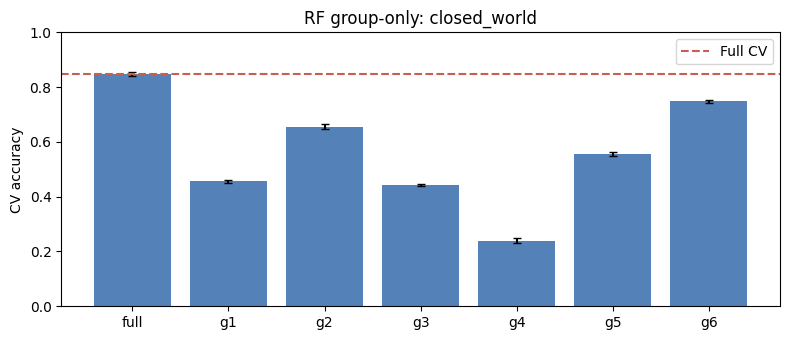

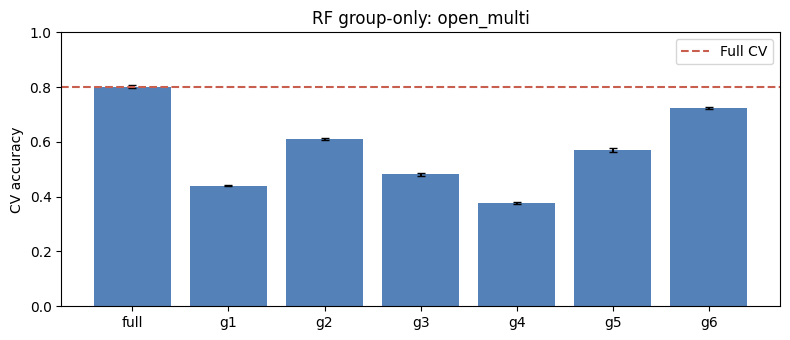

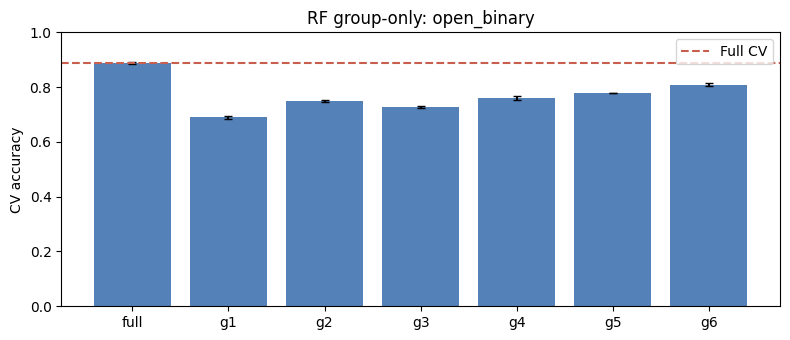

저장 완료: /content/drive/MyDrive/MLB-Project/results/rf_experiment1_group_only/runs/43e4066e7ce4c6ecb12a03f7fbd3be50


In [47]:
summary = save_summary()
paired = []
for task in TASKS:
    if (task,"full") not in RESULTS: continue
    base_row = RESULTS[(task,"full")]
    if base_row["status"] != "complete": continue
    full = pd.read_csv(Path(base_row["result_folder"])/"cv_folds.csv")
    for group in GROUP_SIZES:
        r = RESULTS.get((task,group))
        if r is None or r["status"] != "complete": continue
        gf = pd.read_csv(Path(r["result_folder"])/"cv_folds.csv")
        m = gf.merge(full,on="fold",suffixes=("_only","_full"),validate="one_to_one")
        for _,x in m.iterrows():
            rec = dict(task=task,group=group,fold=int(x.fold),
                       delta_acc=float(x.acc_only-x.acc_full))
            if task == "open_multi":
                rec["delta_mon_site_exact"] = float(x.mon_site_exact_only-x.mon_site_exact_full)
            paired.append(rec)
if paired: atomic_csv(pd.DataFrame(paired),RUN_DIR/"paired_fold_differences.csv")

report_rows = []
for task in TASKS:
    for group in CONDITIONS:
        r = RESULTS.get((task,group))
        if r is None: continue
        if r["status"] != "complete":
            report_rows.append(dict(task=task,group=group,status=r["status"]))
            continue
        s = summary.loc[(summary.task==task)&(summary.group==group)].iloc[0]
        report_rows.append(dict(task=task,group=group,n_features=r["n_features"],
            cv_accuracy=f"{r['cv_acc']:.4f} ± {r['cv_std']:.4f}",
            delta_cv_vs_full=round(float(s.delta_cv_vs_full),4),
            test_accuracy=round(r["test_acc"],4),test_macro_f1=round(r["test_macro_f1"],4),
            test_mon_site_exact=r.get("test_mon_site_exact"),
            test_mon_as_mon=r.get("test_mon_as_mon"),
            test_unmon_as_unmon=r.get("test_unmon_as_unmon"),
            ) )
report = pd.DataFrame(report_rows)
atomic_csv(report,RUN_DIR/"rf_group_only_report_table.csv")
display(report.round(4))

# 그림에는 특징 선택 근거인 CV만 표시합니다. 한글 폰트 설치 없이 표시할 수 있도록 영문 라벨을 씁니다.
for task in TASKS:
    plot_df = summary.loc[(summary.task==task)&(summary.status=="complete")]
    if plot_df.empty: continue
    fig,ax = plt.subplots(figsize=(8,3.5))
    ax.bar(plot_df.group,plot_df.cv_acc,yerr=plot_df.cv_std,capsize=3,color="#5481b8")
    if (plot_df.group=="full").any():
        ax.axhline(plot_df.loc[plot_df.group=="full","cv_acc"].iloc[0],color="#c85f4e",linestyle="--",label="Full CV")
    ax.set(ylim=(0,1),ylabel="CV accuracy",title=f"RF group-only: {task}")
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR/f"{task}_cv_comparison.png",dpi=160)
    plt.show()
    plt.close(fig)

lines = ["# RF 실험 1 · Group-only 결과", "", f"실행 ID: `{RUN_ID}`", "",
         f"고정 RF 설정: {json.dumps(RF_PARAMS,ensure_ascii=False)} / seed={SEED} / 층화 {N_FOLDS}-fold / 분할 상태={split_source}.",
         "보고서 수치는 rf_group_only_report_table.csv를 기준으로 확인하세요.", "",
         "## 결과", "", "| 과제 | 특징 | CV 정확도 | test 정확도 | mon 사이트 정답률(test) |", "|---|---|---|---|---|"]
for r in report_rows:
    if "cv_accuracy" not in r: continue
    mon_exact = "—" if r["test_mon_site_exact"] is None else f"{r['test_mon_site_exact']:.4f}"
    lines.append(f"| {r['task']} | {r['group']} | {r['cv_accuracy']} | {r['test_accuracy']:.4f} | {mon_exact} |")
lines += ["", "## 해석할 때", "",
          "- 단독 성능이 낮다는 이유만으로 그룹을 제거하지 않습니다.",
          "- 기존 Ablation과 합쳐 정보 중복·보완 가능성을 검토하되 이를 확정하지 않습니다.",
          "- 작은 CV 차이, sqrt 규칙에 따른 분기 특징 수 차이, 수집 흔적을 고려합니다.",
          "- 기존 full은 공통 기준으로 남기고, 후속 조합은 별도 검증 후보로만 제안합니다."]
(RUN_DIR/"rf_group_only_report.md").write_text("\n".join(lines)+"\n",encoding="utf-8")
print("저장 완료:", RUN_DIR)


## 8. 기존 Ablation과 연결해서 읽기

단독 실험만으로 최적 조합을 확정하지 않습니다. 이전 `rf_ablation_closed_world_cumul50.csv` 등과 **같은 데이터·분할·고정 RF·전처리 조건인지** 확인하고 비교하세요.
이전 RF 실행에서는 Closed-world와 이진 Ablation만 수행했으므로, **Open-world 다중 Ablation이 있었다고 가정하면 안 됩니다.**

| 단독 결과 | 제거 시 하락 | 가능한 해석 |
| --- | --- | --- |
| 높음 | 큼 | 혼자서도 유용하고 전체에서도 기여할 가능성 |
| 높음 | 작음 | 다른 그룹과 정보가 겹쳐 대체될 가능성 |
| 낮음 | 큼 | 다른 그룹과 결합했을 때 보완적으로 작용할 가능성 |
| 낮음 | 작음 | 현재 모델에서 우선순위가 낮은 후속 검토 후보 |

이 표는 해석의 단서이며 중복·상호작용의 증명은 아닙니다.
예를 들어 g6 단독 성능이 높고 g4 제거 시 성능이 내려갔다면 `g6+g4`를 후속 비교 후보로 둘 수 있습니다.
실제 조합의 성능은 별도 실험으로 확인해야 합니다. 이번 노트북은 조합 탐색이나 실험 2(해상도 비교)를 수행하지 않습니다.

### 저장 파일

모든 파일은 화면에 출력된 `.../rf_experiment1_group_only/runs/<실행ID>/` 아래에 있습니다.

| 파일 | 내용 |
| --- | --- |
| `rf_group_only_summary.csv` | 전체 수치·full 대비 차이·시간·해석 상태 |
| `rf_group_only_report_table.csv` / `rf_group_only_report.md` | 보고서에 옮길 표·해석 메모 |
| `feature_groups.csv` | 그룹별 실제 특징 이름 전체 |
| `config.json`, `split_used.csv`, `*_cv_assignment.csv` | 설정·공유 분할·CV fold 재현 기록 |
| `paired_fold_differences.csv` | 같은 fold의 단독-full 차이 |
| 조건별 폴더 `cv_folds.csv`, `oof_predictions.csv` | 교차검증 점수·학습 데이터 OOF 예측 |
| 조건별 `test_predictions.csv`, `test_mon_site_accuracy.csv` | 최종 예측·사이트별 정답률(다중/Closed) |
| 조건별 `test_confusion_matrix.csv`, `test_confused_pairs.csv` | 혼동 행렬·오류 쌍(다중/Closed) |
| 조건별 `feature_importance.csv` | 불순도 감소 중요도. 인과적 기여·그룹 우열의 증명이 아님 |

**검증 기록:** 노트북 코드의 소규모 실행은 제작 과정에서 점검합니다. 제공된 실제 데이터의 전체 84회 학습 결과가 미리 들어 있는 파일은 아닙니다.
